# Chapter 7 – Dimensionality Reduction
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alirezatheh/handson-mlp-notes/blob/main/notebooks/07_dimensionality_reduction.ipynb)
[![Open in Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/alirezatheh/handson-mlp-notes/blob/main/notebooks/07_dimensionality_reduction.ipynb)

Many machine learning problems involve thousands or even millions of features for each training instance. This not only makes training extremely slow, but can also make it much harder to find a good solution. This problem is often referred to as the *curse of dimensionality*.

**Warning**: Reducing dimensionality can drop some useful information, making our system perform slightly worse, especially if we reduce dimensionality too much. Moreover, some models (such as neural networks) can handle high-dimensional data efficiently and learn to reduce its dimensionality while preserving the useful information for the task at hand. In short, adding an extra preprocessing step for dimensionality reduction will not always help.

## The Curse of Dimensionality
- If we pick a random point in a unit square, it will have only about a 0.4% chance of being located less than 0.001 from a border. In a 10,000-dimensional unit hypercube, this probability is greater than 99.999999%.
- If we pick two points randomly in a unit square, the distance between these two points will be, on average, roughly 0.52. If we pick two random points in a 3D unit cube, it’s 0.66. In a 1,000,000-dimensional unit hypercube it’s 408.25 (roughly $\sqrt{1,000,000/6}$)!

As a result, high-dimensional datasets are often very sparse:
- Most training instances are likely to be far away from each other, so training methods based on distance or similarity (such as *k*-nearest neighbors) will be much less effective.
- Some types of models will not be usable at all because they scale poorly with the dataset’s dimensionality (e.g., SVMs or dense neural networks).
- New instances will likely be far away from any training instance, making predictions much less reliable than in lower dimensions.
- Since patterns in the data will become harder to identify, models will tend to fit the noise more frequently than in lower dimensions; regularization will become all the more important.
- Models will become even harder to interpret.

## Main Approaches for Dimensionality Reduction

### Projection
In most real-world problems, training instances are not spread out uniformly across all dimensions. Many features are almost constant, while others are highly correlated. As a result, all training instances lie within (or close to) a much lower-dimensional *subspace* of the high-dimensional space.

<center>
  <img
    src="../images/07/dataset_3d.png"
    onerror="
      this.onerror = null;
      const repo = 'https://github.com/alirezatheh/handson-mlp-notes/blob/main';
      this.src = repo + this.src.split('..')[1];
    "
  >
</center>

If we project every training instance perpendicularly onto this subspace we have just reduced the dataset’s dimensionality.

<center>
  <img
    src="../images/07/dataset_2d.png"
    onerror="
      this.onerror = null;
      const repo = 'https://github.com/alirezatheh/handson-mlp-notes/blob/main';
      this.src = repo + this.src.split('..')[1];
    "
  >
</center>

### Manifold Learning
A $d$-dimensional *manifold* is a part of an $n$-dimensional space (where $d<n$) that locally resembles a $d$-dimensional hyperplane. In the case of the Swiss roll, $d=2$ and $n=3$: it locally resembles a 2D plane, but it is rolled in the third dimension.

<center>
  <img
    src="../images/07/swiss_roll.png"
    onerror="
      this.onerror = null;
      const repo = 'https://github.com/alirezatheh/handson-mlp-notes/blob/main';
      this.src = repo + this.src.split('..')[1];
    "
  >
</center>

Many dimensionality reduction algorithms (e.g., LLE, Isomap, t-SNE, or UMAP) work by modeling the manifold on which the training instances lie; this is called *manifold learning*. It relies on the *manifold assumption*, also called the *manifold hypothesis*, which holds that most real-world high-dimensional datasets lie close to a much lower-dimensional manifold.

<center>
  <img
    src="../images/07/squished_swiss_roll.png"
    onerror="
      this.onerror = null;
      const repo = 'https://github.com/alirezatheh/handson-mlp-notes/blob/main';
      this.src = repo + this.src.split('..')[1];
    "
  >
</center>

The manifold assumption is often accompanied by another implicit assumption: that the task at hand will be simpler if expressed in the lower-dimensional space of the manifold. But this does not always hold:

<center>
  <img
    src="../images/07/manifold_decision_boundary.png"
    onerror="
      this.onerror = null;
      const repo = 'https://github.com/alirezatheh/handson-mlp-notes/blob/main';
      this.src = repo + this.src.split('..')[1];
    "
  >
</center>

In short, reducing the dimensionality of our training set before training a model will usually speed up training, but it may not always lead to a better or simpler solution; it all depends on the dataset. Dimensionality reduction is typically more effective when the dataset is small relative to the number of features, especially if it’s noisy, or many features are highly correlated to one another (i.e., redundant). And if we have domain knowledge about the process that generated the data, and we know it’s simple, then the manifold assumption certainly holds, and dimensionality reduction is likely to help.

## PCA
*Principal component analysis* (PCA) is by far the most popular dimensionality reduction algorithm. First it identifies the hyperplane that lies closest to the data, and then it projects the data onto it.

### Preserving the Variance
It seems reasonable to select the axis that preserves the maximum amount of variance, as it will most likely lose less information than the other projections (consider our shadow on the ground when the sun is directly overhead: it’s a small blob that doesn’t look anything like us, but our shadow on a wall at sunrise is much larger and it *does* look like us). Another way to justify choosing the axis that maximizes the variance is that it is also the axis that minimizes the mean squared distance between the original dataset and its projection onto that axis. This is the rather simple idea behind PCA proposed by Karl Pearson in a 1901 paper [“On Lines and Planes of Closest Fit to Systems of Points in Space”](https://homl.info/pca).

<center>
  <img
    src="../images/07/pca_best_projection.png"
    onerror="
      this.onerror = null;
      const repo = 'https://github.com/alirezatheh/handson-mlp-notes/blob/main';
      this.src = repo + this.src.split('..')[1];
    "
  >
</center>

### Principal Components
PCA identifies the axis that accounts for the largest amount of variance in the training set. It also finds a second axis, orthogonal to the first one, that accounts for the largest amount of the remaining variance. If it were a higher-dimensional dataset, PCA would also find a third axis, orthogonal to both previous axes and so on.

The $i^\text{th}$ axis is called the $i^\text{th}$ *principal component* (PC) of the data. For each PC, PCA finds a zero-centered unit vector pointing along the direction of the PC. Its direction is not guaranteed: if we perturb the training set slightly and run PCA again, the unit vector may point in the opposite direction. In fact, a pair of unit vectors may even rotate or swap if the variances along these two axes are very close. So if we use PCA as a preprocessing step before a model, we should always retrain the model entirely every time we update the PCA transformer, otherwise the model will be very confused.

To find the principal components of a training set we use a standard matrix factorization technique called *singular value decomposition* (SVD) which decomposes the training set matrix $\mathbf{X}$ into the product of three matrices $\mathbf{U}\mathbf{\Sigma}\mathbf{V}^\top$, where $\mathbf{V}$ contains the unit vectors that define all the principal components that we are looking for, in the correct order (the proof requires some math, such as eigenvectors and covariance matrices, see this [2014 paper by Jonathon Shlens](https://homl.info/pca2)):

**Equation 7-1** Principal components matrix
$$
\mathbf{V}
=\begin{pmatrix}|&|&&|
\\\mathbf{c}_1&\mathbf{c}_2&&\mathbf{c}_n
\\|&|&&|
\end{pmatrix}
$$

Let’s use NumPy’s `svd()` function to obtain all the principal components of a 3D training set:

In [1]:
import numpy as np
from scipy.spatial.transform import Rotation

# Creating a small 3D dataset
m = 60
X = np.zeros((m, 3))
rng = np.random.default_rng(seed=42)
# Uneven distribution
angles = (rng.random(m) ** 3 + 0.5) * 2 * np.pi
# Oval
X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5
# Add more noise
X += 0.28 * rng.standard_normal((m, 3))
X = Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]).apply(X)
# Shift a bit
X += [0.2, 0, 0.2]

# PCA assumes that the dataset is centered around the origin
X_centered = X - X.mean(axis=0)
U, s, Vt = np.linalg.svd(X_centered)
c1 = Vt[0]
c2 = Vt[1]

**Warning**: PCA assumes that the dataset is centered around the origin. Scikit-Learn’s PCA classes take care of centering the data for us. If we implement PCA ourself, or if we use other libraries, don’t forget to center the data first.

**Note**: In principle, $\mathbf{U}$ is an $m\times m$ matrix, $\mathbf{\Sigma}$ is an $m\times n$ matrix, and $\mathbf{V}$ is an $n\times n$ matrix. But the `svd()` function returns $\mathbf{U}$, $\mathbf{s}$ and $\mathbf{V}^\top$ instead. $\mathbf{s}$ is the vector containing all the values on the main diagonal of the top $n$ rows of $\mathbf{\Sigma}$. Since $\mathbf{\Sigma}$ is full of zeros elsewhere, we can easily reconstruct it from $\mathbf{s}$, like this:

In [2]:
# How to construct Σ from s
m, n = X.shape
Σ = np.zeros_like(X_centered)
Σ[:n, :n] = np.diag(s)
assert np.allclose(X_centered, U @ Σ @ Vt)

### Projecting Down to d Dimensions
**Equation 7-2**
$$
\mathbf{X}_{d\text{-proj}}=\mathbf{X}\mathbf{W}_d
$$
- $\mathbf{W}_d$: Defined as the matrix containing the first $d$ columns of $\mathbf{V}$

In [3]:
W2 = Vt[:2].T
X2D = X_centered @ W2

### Using Scikit-Learn

In [4]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X2D = pca.fit_transform(X)

In [5]:
pca.components_

array([[ 0.66824153,  0.73208333,  0.13231495],
       [ 0.74374636, -0.66151587, -0.09611511]])

### Explained Variance Ratio
The ratio indicates the proportion of the dataset’s variance that lies along each principal component.

In [6]:
pca.explained_variance_ratio_

array([0.82279334, 0.10821224])

### Choosing the Right Number of Dimensions
Choose the number of dimensions that add up to a sufficiently large portion of the variance say, 95%.

In [7]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784", as_frame=False)
X_train, y_train = mnist.data[:60_000], mnist.target[:60_000]
X_test, y_test = mnist.data[60_000:], mnist.target[60_000:]

pca = PCA()
pca.fit(X_train)
cumsum = np.cumsum(pca.explained_variance_ratio_)
d = np.argmax(cumsum >= 0.95) + 1

In [8]:
d

np.int64(154)

We can also set `n_components` to be a float between 0.0 and 1.0, indicating the ratio of variance we wish to preserve:

In [9]:
pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X_train)

In [10]:
pca.n_components_

np.int64(154)

In [11]:
pca.explained_variance_ratio_.sum()

np.float64(0.9501960192613034)

Another option is to plot the explained variance as a function of the number of dimensions:

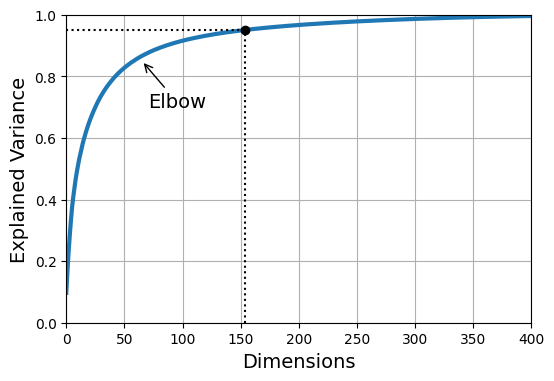

In [12]:
import matplotlib.pyplot as plt

plt.rc("font", size=14)
plt.rc("axes", labelsize=14, titlesize=14)
plt.rc("legend", fontsize=14)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)

plt.figure(figsize=(6, 4))
plt.plot(cumsum, linewidth=3)
plt.axis([0, 400, 0, 1])
plt.xlabel("Dimensions")
plt.ylabel("Explained Variance")
plt.plot([d, d], [0, 0.95], "k:")
plt.plot([0, d], [0.95, 0.95], "k:")
plt.plot(d, 0.95, "ko")
plt.annotate(
    "Elbow", xy=(65, 0.85), xytext=(70, 0.7), arrowprops=dict(arrowstyle="->")
)
plt.grid(True)
plt.show()

Alternatively, if we are using dimensionality reduction as a preprocessing step for a supervised learning task (e.g., classification), then we can tune the number of dimensions using random or grid search.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline

clf = make_pipeline(
    PCA(random_state=42), RandomForestClassifier(random_state=42)
)
param_distrib = {
    "pca__n_components": np.arange(10, 80),
    "randomforestclassifier__n_estimators": np.arange(50, 500),
}
rnd_search = RandomizedSearchCV(
    clf, param_distrib, n_iter=10, cv=3, random_state=42
)
rnd_search.fit(X_train[:1000], y_train[:1000])

,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'pca__n_components': array([10, 11... 78, 79]), 'randomforestclassifier__n_estimators': array([ 50, ...97, 498, 499])}"
,n_iter,10
,scoring,None
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [14]:
print(rnd_search.best_params_)

{'randomforestclassifier__n_estimators': np.int64(475), 'pca__n_components': np.int64(57)}


In [15]:
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV

clf = make_pipeline(PCA(random_state=42), SGDClassifier())
param_grid = {"pca__n_components": np.arange(10, 80)}
grid_search = GridSearchCV(clf, param_grid, cv=3)
grid_search.fit(X_train[:1000], y_train[:1000])

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'pca__n_components': array([10, 11... 78, 79])}"
,scoring,None
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_components,np.int64(69)


In [16]:
grid_search.best_params_

{'pca__n_components': np.int64(69)}

**Note**: We may also care about the model’s size and speed, not just its performance. The fewer dimensions, the smaller the model, and the faster training and inference will be. But if we shrink the data too much, then we will lose too much signal and our model will underfit. We need to choose the right balance of speed, size, and performance for our particular use case.

### PCA for Compression
We saw that after applying PCA to the MNIST dataset while preserving 95% of its variance, we are left with 154 features, instead of the original 784 features.

In [17]:
pca = PCA(0.95)
X_reduced = pca.fit_transform(X_train, y_train)

In [18]:
X_recovered = pca.inverse_transform(X_reduced)

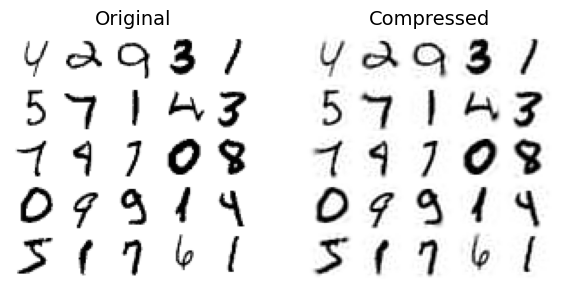

In [19]:
plt.figure(figsize=(7, 4))
for idx, X in enumerate((X_train[::2100], X_recovered[::2100])):
    plt.subplot(1, 2, idx + 1)
    plt.title(["Original", "Compressed"][idx])
    for row in range(5):
        for col in range(5):
            plt.imshow(
                X[row * 5 + col].reshape(28, 28),
                cmap="binary",
                vmin=0,
                vmax=255,
                extent=(row, row + 1, col, col + 1),
            )
            plt.axis([0, 5, 0, 5])
            plt.axis("off")

**Equation 7-3** PCA inverse transformation, back to the original number of dimensions
$$
\mathbf{X}_{\text{recovered}}=\mathbf{X}_{d\text{-proj}}{\mathbf{W}_d}^\top
$$

### Randomized PCA
If we set `svd_solver='randomized'`, Scikit-Learn uses a stochastic algorithm called *randomized PCA* that quickly finds an approximation of the first $d$ principal components. Its computational complexity is $O(m\times d^2)+O(d^3)$, instead of $O(m\times n^2)+O(n^3)$ for the full SVD approach.

In [20]:
rnd_pca = PCA(n_components=154, svd_solver="randomized", random_state=42)
X_reduced = rnd_pca.fit_transform(X_train)

**Tip**: By default, `svd_solver='auto'`: if the input data has few features ($n<1{,}000$) and at least 10 times more samples ($m>10n$), then the `'covariance_eigh'` solver is used, which is very fast in these conditions. Otherwise, if $\max(m,n)>500$ and `n_components` is an integer smaller than 80% of $\min(m,n)$, it uses the `'randomized'` solver. In other cases, it uses the full SVD approach. If we want to force Scikit-Learn to use full SVD, trading compute time for a slightly more precise result, we can set `svd_solver='full'`.

### Incremental PCA
*Incremental PCA* (IPCA) algorithms have been developed that allow us to split the training set into mini-batches and feed these in one mini-batch at a time (Scikit-Learn uses the algorithm described in the paper [“Incremental Learning for Robust Visual Tracking”](https://homl.info/32) by David A. Ross et al. in 2008).

In [21]:
from sklearn.decomposition import IncrementalPCA

n_batches = 100
inc_pca = IncrementalPCA(n_components=154)
for X_batch in np.array_split(X_train, n_batches):
    inc_pca.partial_fit(X_batch)

X_reduced = inc_pca.transform(X_train)

Alternatively we can use NumPy’s `memmap` class (a memory-map to an array stored in a binary file on disk).

Let’s create the `memmap` instance, copy the MNIST training set into it, and call `flush()` which ensures that any data still in cache is saved to disk. This would typically be done by a first program:

In [22]:
filename = "my_mnist.mmap"
X_mmap = np.memmap(
    filename, dtype="float32", mode="write", shape=X_train.shape
)
# Could be a loop instead, saving the data chunk by chunk
X_mmap[:] = X_train
X_mmap.flush()

Next, another program would load the data and use it for training:

In [23]:
X_mmap = np.memmap(filename, dtype="float32", mode="readonly").reshape(-1, 784)
batch_size = X_mmap.shape[0] // n_batches
inc_pca = IncrementalPCA(n_components=154, batch_size=batch_size)
inc_pca.fit(X_mmap)

,n_components,154
,whiten,False
,copy,True
,batch_size,600


**Warning**: Only the raw binary data is saved to disk, so we need to specify the data type and shape of the array when we load it. If we omit the shape, `np.memmap()` returns a 1D array.

## Random Projection
If we are dealing with a dataset with tens of thousands of features or more (e.g., images), then training may become much too slow: in this case, we should consider using random projection instead. As its name suggests, the random projection algorithm projects the data to a lower-dimensional space using a random linear projection. William B. Johnson and Joram Lindenstrauss in a famous lemma demonstrated mathematically that this is very likely to preserve distances fairly well. They came up with an equation that determines the minimum number of dimensions to preserve in order to ensure (with high probability) that distances won’t change by more than a given tolerance:
$$d\geq4\log(m)/(\tfrac{1}{2}\varepsilon^2-\tfrac{1}{3}\varepsilon^3)$$

**Warning**: This section will use close to 2.5 GB of RAM. If our computer runs out of memory, we should just reduce $m$ and $n$:

In [24]:
from sklearn.random_projection import johnson_lindenstrauss_min_dim

m, ε = 5_000, 0.1
d = johnson_lindenstrauss_min_dim(m, eps=ε)
d

np.int64(7300)

In [25]:
d = int(4 * np.log(m) / (ε**2 / 2 - ε**3 / 3))
d

7300

Now we can just generate a random matrix $\mathbf{P}$ of shape $[d,n]$, where each item is sampled randomly from a Gaussian distribution with mean 0 and variance $1/d$, and use it to project a dataset from $n$ dimensions down to $d$:

In [26]:
n = 20_000
rng = np.random.default_rng(seed=42)
# Gaussian distribution with mean 0 and variance 1/d
P = rng.standard_normal((d, n)) / np.sqrt(d)

# Generate a fake dataset
X = rng.standard_normal((m, n))
X_reduced = X @ P.T

Training is almost instantaneous: the only thing the algorithm needs to create the random matrix is the dataset’s shape. This makes random projection particularly well suited for very high-dimensional data such as text or genomics with millions of features, or very sparse data, for which even randomized PCA may take too long to train and require too much memory. At inference time, random projection is just as fast as PCA (i.e., one matrix multiplication). However, it loses a bit more signal than PCA, so there’s a trade-off between training speed and performance.

Scikit-Learn’s `GaussianRandomProjection` class does exactly what we just did:

In [27]:
from sklearn.random_projection import GaussianRandomProjection

gaussian_rnd_proj = GaussianRandomProjection(eps=ε, random_state=42)
# Same result as above
X_reduced = gaussian_rnd_proj.fit_transform(X)

We can also tweak `n_components` to force a specific target dimensionality (we will probably want to fine-tune `eps` and `n_components` using cross-validation).

To get the inverse transform, we first need to compute the pseudoinverse of the components matrix:

**Warning**: The following cell may take several minutes to run, since `pinv()` is $O(dn^2)$ if $d<n$, or $O(nd^2)$ otherwise.

In [28]:
components_pinv = np.linalg.pinv(gaussian_rnd_proj.components_)
X_recovered = X_reduced @ components_pinv.T

Scikit-Learn also provides a `SparseRandomProjection` class, which works the same way except that the random matrix is sparse, so it is much more memory efficient.

The ratio $r$ of nonzero items in the sparse random matrix is called its *density*. By default, it is equal to $1/\sqrt{n}$. We can set the `density` hyperparameter. Each cell in the sparse random matrix has a probability $r$ of being nonzero, and each nonzero value is either $–v$ or $+v$ (both equally likely), where $v = 1/\sqrt{dr}$.

In [29]:
# Performance comparison between Gaussian and Sparse RP
from sklearn.random_projection import SparseRandomProjection

print("GaussianRandomProjection fit")
%timeit GaussianRandomProjection(random_state=42).fit(X)
print("SparseRandomProjection fit")
%timeit SparseRandomProjection(random_state=42).fit(X)

gaussian_rnd_proj = GaussianRandomProjection(random_state=42).fit(X)
sparse_rnd_proj = SparseRandomProjection(random_state=42).fit(X)
print("GaussianRandomProjection transform")
%timeit gaussian_rnd_proj.transform(X)
print("SparseRandomProjection transform")
%timeit sparse_rnd_proj.transform(X)

GaussianRandomProjection fit
1.5 s ± 46 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
SparseRandomProjection fit
873 ms ± 11.6 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
GaussianRandomProjection transform
2 s ± 30.5 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
SparseRandomProjection transform
1.6 s ± 46.7 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


## LLE
*Locally linear embedding* (LLE) proposed by Sam T. Roweis and Lawrence K. Saul in a 2000 paper [“Nonlinear Dimensionality Reduction by Locally Linear Embedding”](https://homl.info/lle) is a nonlinear dimensionality reduction (NLDR) technique. It is a manifold learning technique which works by first measuring how each training instance linearly relates to its nearest neighbors, and then looking for a low-dimensional representation of the training set where these local relationships are best preserved. This approach makes it particularly good at unrolling twisted manifolds, especially when there is not too much noise. However, it does not scale well, so it is mostly for small or medium-sized datasets.

Let’s make a Swiss roll, then unroll it:

In [30]:
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import LocallyLinearEmbedding

X_swiss, t = make_swiss_roll(n_samples=1000, noise=0.2, random_state=42)
lle = LocallyLinearEmbedding(n_components=2, n_neighbors=10, random_state=42)
X_unrolled = lle.fit_transform(X_swiss)

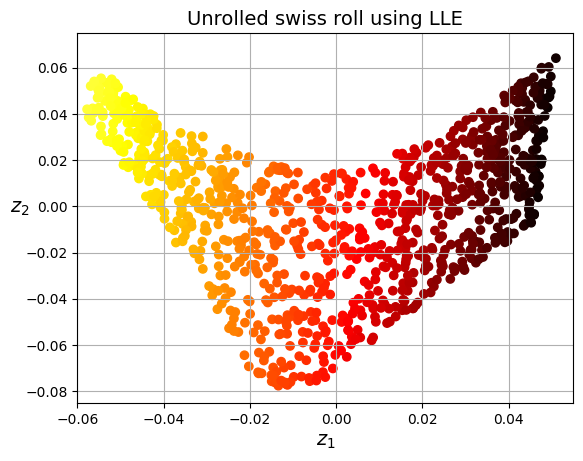

In [31]:
from matplotlib.colors import ListedColormap

darker_hot = ListedColormap(plt.cm.hot(np.linspace(0, 0.8, 256)))

plt.scatter(X_unrolled[:, 0], X_unrolled[:, 1], c=t, cmap=darker_hot)
plt.xlabel("$z_1$")
plt.ylabel("$z_2$", rotation=0)
plt.axis([-0.06, 0.055, -0.085, 0.075])
plt.grid(True)

plt.title("Unrolled swiss roll using LLE")
plt.show()

Here’s how LLE works: for each training instance $\mathbf{x}^{(i)}$, the algorithm identifies its *k*-nearest neighbors, then tries to reconstruct $\mathbf{x}^{(i)}$ as a linear function of these neighbors. It tries to find the weights $w_{i,j}$ such that the squared distance between $\mathbf{x}^{(i)}$ and $\sum_{j=1}^mw_{i,j}\mathbf{x}^{(j)}$ is as small as possible, assuming $w_{i,j}=0$ if $\mathbf{x}^{(j)}$ is not one of the *k*-nearest neighbors of $\mathbf{x}^{(i)}$.

**Equation 7-4** LLE step 1: linearly modeling local relationships
$$
\begin{split}
&\widehat{\mathbf{W}}
=\underset{\mathbf{W}}{\text{argmin}}
\sum_{i=1}^m\left(\mathbf{x}^{(i)}-\sum_{j=1}^mw_{i,j}\mathbf{x}^{(j)}\right)^2
\\&\text{subject to}\;
\begin{cases}
w_{i,j}=0
&\text{if $\mathbf{x}^{(j)}$ is not one of the $k$ n.n of $\mathbf{x}^{(i)}$}
\\\sum_{j=1}^mw_{i,j}=1&\text{for}\;i=1,2,\cdots,m
\end{cases}
\end{split}
$$
The second step is to map the training instances into a $d$-dimensional space (where $d<n$) while preserving these local relationships as much as possible.

**Equation 7-5** LLE step 2: reducing dimensionality while preserving relationships
$$
\widehat{\mathbf{Z}}
=\underset{\mathbf{Z}}{\text{argmin}}
\sum_{i=1}^m\left(\mathbf{z}^{(i)}-\sum_{j=1}^mw_{i,j}\mathbf{z}^{(j)}\right)^2
$$
- $\mathbf{z}^{(i)}$: the image of $\mathbf{x}^{(i)}$ in this $d$-dimensional
  space

Scikit-Learn’s LLE Computational complexity:
- For finding the k-nearest neighbors: $O(m\log(m)n\log(k))$
- For optimizing the weights: $O(mnk^3)$
- For constructing the low-dimensional representation: $O(dm^2)$

Scales poorly with $m$ because of $m^2$.

## Other Dimensionality Reduction Techniques
<style>ul {list-style-type: none;}</style>

`sklearn.manifold.MDS`
- *Multidimensional scaling* (MDS) reduces dimensionality while trying to preserve the distances between the instances. Random projection does that for high-dimensional data, but it doesn’t work well on low-dimensional data.

In [32]:
from sklearn.manifold import MDS

mds = MDS(n_components=2, n_init=4, random_state=42)
X_reduced_mds = mds.fit_transform(X_swiss)

<style>ul {list-style-type: none;}</style>

`sklearn.manifold.Isomap`
- *Isomap* creates a graph by connecting each instance to its nearest neighbors, then reduces dimensionality while trying to preserve the geodesic distances between the instances. The geodesic distance between two nodes in a graph is the number of nodes on the shortest path between these nodes. This approach works best when the data lies on a fairly smooth and low-dimensional manifold with a single global structure (e.g., the Swiss roll).

In [33]:
from sklearn.manifold import Isomap

isomap = Isomap(n_components=2)
X_reduced_isomap = isomap.fit_transform(X_swiss)

<style>ul {list-style-type: none;}</style>

`sklearn.manifold.TSNE`
- *t-distributed stochastic neighbor embedding* (t-SNE) reduces dimensionality while trying to keep similar instances close and dissimilar instances apart. It is mostly used for visualization, in particular to visualize clusters of instances in high-dimensional space. However, it is not meant to be used as a preprocessing stage for an ML model.

**Tip**: *Uniform Manifold Approximation and Projection* (UMAP) is another popular dimensionality reduction technique for visualization. While t-SNE is better at preserving the local structure, especially clusters, UMAP tries to preserve both the local and global structures. Moreover, it scales better to large datasets. It is not available in Scikit-Learn, but there’s a good implementation in the [umap-learn package](https://umap-learn.readthedocs.io).

In [34]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2, init="random", learning_rate="auto", random_state=42
)
X_reduced_tsne = tsne.fit_transform(X_swiss)

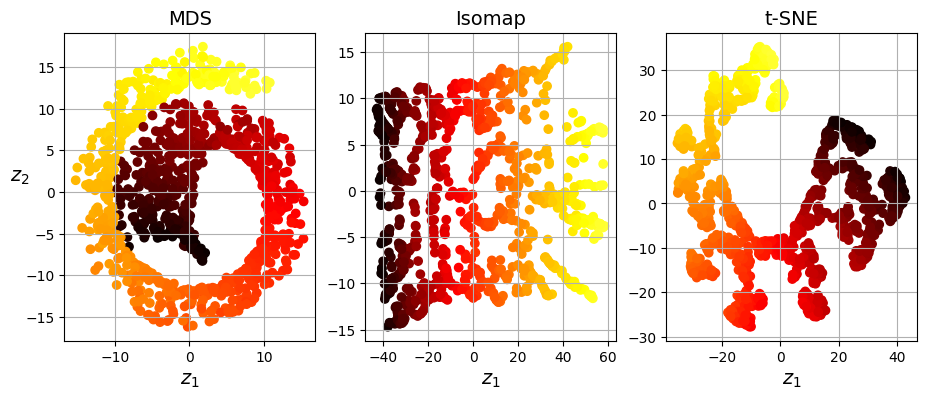

In [35]:
titles = ["MDS", "Isomap", "t-SNE"]

plt.figure(figsize=(11, 4))

for subplot, title, X_reduced in zip(
    (131, 132, 133), titles, (X_reduced_mds, X_reduced_isomap, X_reduced_tsne)
):
    plt.subplot(subplot)
    plt.title(title)
    plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=t, cmap=darker_hot)
    plt.xlabel("$z_1$")
    if subplot == 131:
        plt.ylabel("$z_2$", rotation=0)
    plt.grid(True)

plt.show()

<style>ul {list-style-type: none;}</style>

`sklearn.discriminant_analysis.LinearDiscriminantAnalysis`
- *Linear discriminant analysis* (LDA) is a linear classification algorithm that, during training, learns the most discriminative axes between the classes. These axes can then be used to define a hyperplane onto which to project the data. The benefit of this approach is that the projection will keep classes as far apart as possible, so LDA is a good technique to reduce dimensionality before running another classification algorithm (unless LDA alone is sufficient).

## Extra Material - Kernel PCA

In [36]:
from sklearn.decomposition import KernelPCA

rbf_pca = KernelPCA(n_components=2, kernel="rbf", gamma=0.04, random_state=42)
X_reduced = rbf_pca.fit_transform(X_swiss)

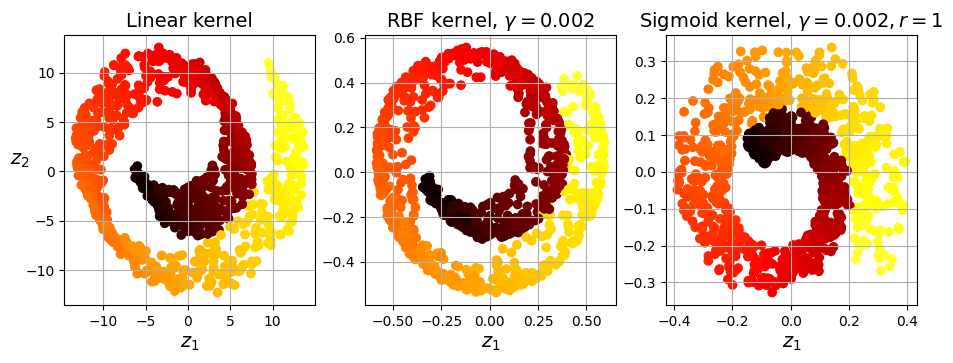

In [37]:
lin_pca = KernelPCA(kernel="linear")
rbf_pca = KernelPCA(kernel="rbf", gamma=0.002)
sig_pca = KernelPCA(kernel="sigmoid", gamma=0.002, coef0=1)

kernel_pcas = (
    (lin_pca, "Linear kernel"),
    (rbf_pca, rf"RBF kernel, $\gamma={rbf_pca.gamma}$"),
    (sig_pca, rf"Sigmoid kernel, $\gamma={sig_pca.gamma}, r={sig_pca.coef0}$"),
)

plt.figure(figsize=(11, 3.5))
for idx, (kpca, title) in enumerate(kernel_pcas):
    kpca.n_components = 2
    kpca.random_state = 42
    X_reduced = kpca.fit_transform(X_swiss)

    plt.subplot(1, 3, idx + 1)
    plt.title(title)
    plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=t, cmap=darker_hot)
    plt.xlabel("$z_1$")
    if idx == 0:
        plt.ylabel("$z_2$", rotation=0)
    plt.grid()

plt.show()

## Exercises

### 1. to 9.
1. What are the main motivations for reducing a dataset’s dimensionality? What are the main drawbacks?
> The main motivations for dimensionality reduction are:
> - To speed up a subsequent training algorithm (in some cases it may even remove noise and redundant features, making the training algorithm perform better)
> - To visualize the data and gain insights on the most important features
> - To save space (compression)
>
> The main drawbacks are:
> - Some information is lost, possibly degrading the performance of subsequent training algorithms.
> - It can be computationally intensive.
> - It adds some complexity to our ML pipelines.
> - Transformed features are often hard to interpret.
2. What is the curse of dimensionality?
> The curse of dimensionality refers to the fact that many problems that do not exist in low-dimensional space arise in high-dimensional space. In machine learning, one common manifestation is the fact that randomly sampled high-dimensional vectors are generally far from one another, increasing the risk of overfitting and making it very difficult to identify patterns without having plenty of training data.
3. Once a dataset’s dimensionality has been reduced, is it possible to reverse the operation? If so, how? If not, why?
> It is almost always impossible to perfectly reverse the operation, because some information gets lost during dimensionality reduction. Moreover, while some algorithms (such as PCA) have a simple reverse transformation procedure that can reconstruct a dataset relatively similar to the original, other algorithms (such as t-SNE) do not.
4. Can PCA be used to reduce the dimensionality of a highly nonlinear dataset?
> Yes, because it can at least get rid of useless dimensions. However, if there are no useless dimensions (as in the Swiss roll dataset) then reducing dimensionality with PCA will lose too much information. We want to unroll the Swiss roll, not squash it.
5. Suppose we perform PCA on a 1,000-dimensional dataset, setting the explained variance ratio to 95%. How many dimensions will the resulting dataset have?
> That’s a trick question: it depends on the dataset. Let’s look at two extreme examples. First, suppose the dataset is composed of points that are almost perfectly aligned. In this case, PCA can reduce the dataset down to just one dimension while still preserving 95% of the variance. Now imagine that the dataset is composed of perfectly random points, scattered all around the 1,000 dimensions. In this case roughly 950 dimensions are required to preserve 95% of the variance. So the answer is, it depends on the dataset, and it could be any number between 1 and 950. Plotting the explained variance as a function of the number of dimensions is one way to get a rough idea of the dataset’s intrinsic dimensionality.
6. In what cases would we use regular PCA, incremental PCA, randomized PCA, or random projection?
> Regular PCA is the default, but it works only if the dataset fits in memory. Incremental PCA is useful for large datasets that don’t fit in memory, but it is slower than regular PCA, so if the dataset fits in memory we should prefer regular PCA. Incremental PCA is also useful for online tasks, when we need to apply PCA on the fly, every time a new instance arrives. Randomized PCA is useful when we want to considerably reduce dimensionality and the dataset fits in memory; in this case, it is much faster than regular PCA. Finally, random projection is great for very high-dimensional datasets.
7. How can we evaluate the performance of a dimensionality reduction algorithm on our dataset?
> Intuitively, a dimensionality reduction algorithm performs well if it eliminates a lot of dimensions from the dataset without losing too much information. One way to measure this is to apply the reverse transformation and measure the reconstruction error. However, not all dimensionality reduction algorithms provide a reverse transformation. Alternatively, if we are using dimensionality reduction as a preprocessing step before another ML algorithm (e.g., a random forest classifier), then we can simply measure the performance of that second algorithm; if dimensionality reduction did not lose too much information, then the algorithm should perform just as well as when using the original dataset.
8. Does it make any sense to chain two different dimensionality reduction algorithms?
> Yes. A common example is using PCA or Random Projection to quickly get rid of a large number of useless dimensions, then applying another much slower dimensionality reduction algorithm, such as LLE. This two-step approach will likely yield roughly the same performance as using LLE only, but in a fraction of the time.
9. Load the MNIST dataset (introduced in chapter 3) and split it into a training set and a test set (take the first 60,000 instances for training, and the remaining 10,000 for testing).
> The MNIST dataset was loaded earlier.

In [38]:
X_train = mnist.data[:60000]
y_train = mnist.target[:60000]

X_test = mnist.data[60000:]
y_test = mnist.target[60000:]

Train a random forest classifier on the dataset and time how long it takes, then evaluate the resulting model on the test set.

In [39]:
rnd_clf = RandomForestClassifier(n_estimators=100, random_state=42)

In [40]:
%time rnd_clf.fit(X_train, y_train)

CPU times: user 21.2 s, sys: 597 ms, total: 21.8 s
Wall time: 22 s


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [41]:
from sklearn.metrics import accuracy_score

y_pred = rnd_clf.predict(X_test)
accuracy_score(y_test, y_pred)

0.9691

Next, use PCA to reduce the dataset’s dimensionality, with an explained variance ratio of 95%.

In [42]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)
X_train_reduced = pca.fit_transform(X_train)

Train a new random forest classifier on the reduced dataset and see how long it takes. Was training much faster?

In [43]:
rnd_clf_with_pca = RandomForestClassifier(n_estimators=100, random_state=42)
%time rnd_clf_with_pca.fit(X_train_reduced, y_train)

CPU times: user 1min 1s, sys: 1.38 s, total: 1min 3s
Wall time: 1min 3s


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


> Oh no! Training is actually about three times slower now! How can that be? Well, as we saw in this chapter, dimensionality reduction does not always lead to faster training time: it depends on the dataset, the model and the training algorithm. If we try `SGDClassifier` instead of `RandomForestClassifier`, we will find that training time is reduced by a factor of 3 when using PCA. Actually, we will do this in a second, but first let’s check the precision of the new random forest classifier.

Next evaluate the classifier on the test set. how does it compare to the previous classifier?

In [44]:
X_test_reduced = pca.transform(X_test)

y_pred = rnd_clf_with_pca.predict(X_test_reduced)
accuracy_score(y_test, y_pred)

0.9487

> It is common for performance to drop slightly when reducing dimensionality, because we do lose some potentially useful signal in the process. However, the performance drop is rather severe in this case. So PCA really did not help: it slowed down training *and* reduced performance. 😭

Try again with an `SGDClassifier`. How much does PCA help now?

In [45]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
%time sgd_clf.fit(X_train, y_train)

CPU times: user 1min 11s, sys: 1.61 s, total: 1min 13s
Wall time: 1min 14s


,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


In [46]:
y_pred = sgd_clf.predict(X_test)
accuracy_score(y_test, y_pred)

0.874

> Okay, so the `SGDClassifier` takes much longer to train on this dataset than the `RandomForestClassifier`, plus it performs worse on the test set. But that’s not what we are interested in right now, we want to see how much PCA can help `SGDClassifier`. Let’s train it using the reduced dataset:

In [47]:
sgd_clf_with_pca = SGDClassifier(random_state=42)
%time sgd_clf_with_pca.fit(X_train_reduced, y_train)

CPU times: user 14.7 s, sys: 326 ms, total: 15 s
Wall time: 15.1 s


,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


> Nice! Reducing dimensionality led to roughly $5\times$ speedup. :) Let’s check the model’s accuracy:

In [48]:
y_pred = sgd_clf_with_pca.predict(X_test_reduced)
accuracy_score(y_test, y_pred)

0.8959

> Great! PCA not only gave us a $5\times$ speed boost, it also improved performance slightly.
>
> So there we have it: PCA can give us a formidable speedup, and if we’re lucky a performance boost... but it’s really not guaranteed: it depends on the model and the dataset!

### 10.
Use t-SNE to reduce the first 5,000 images of the MNIST dataset down to two dimensions and plot the result using Matplotlib. We can use a scatterplot using 10 different colors to represent each image’s target class.
> Let’s limit ourselves to the first 5,000 images of the MNIST training set, to speed things up a lot.

In [49]:
X_sample, y_sample = X_train[:5000], y_train[:5000]

> Let’s use t-SNE to reduce dimensionality down to 2D so we can plot the dataset:

In [50]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2, init="random", learning_rate="auto", random_state=42
)
%time X_reduced = tsne.fit_transform(X_sample)

CPU times: user 36 s, sys: 23.9 s, total: 59.9 s
Wall time: 5.8 s


> Now let’s use Matplotlib’s `scatter()` function to plot a scatterplot, using a different color for each digit:

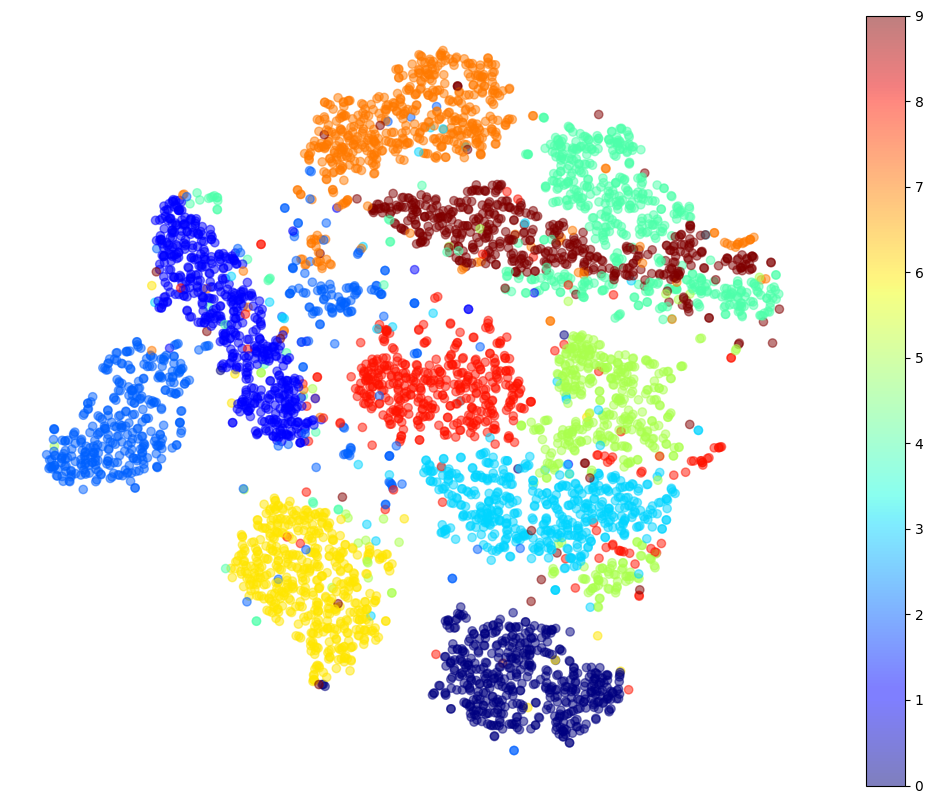

In [51]:
plt.figure(figsize=(13, 10))
plt.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=y_sample.astype(np.int8),
    cmap="jet",
    alpha=0.5,
)
plt.axis("off")
plt.colorbar()
plt.show()

> Isn’t this just beautiful? :) Most digits are nicely separated from the others, even though t-SNE wasn’t given the targets: it just identified clusters of similar images. But there is still a bit of overlap. For example, the 3s and the 5s overlap a lot (on the right side of the plot), and so do the 4s and the 9s (in the top-right corner). Let’s focus on just the digits 4 and 9:

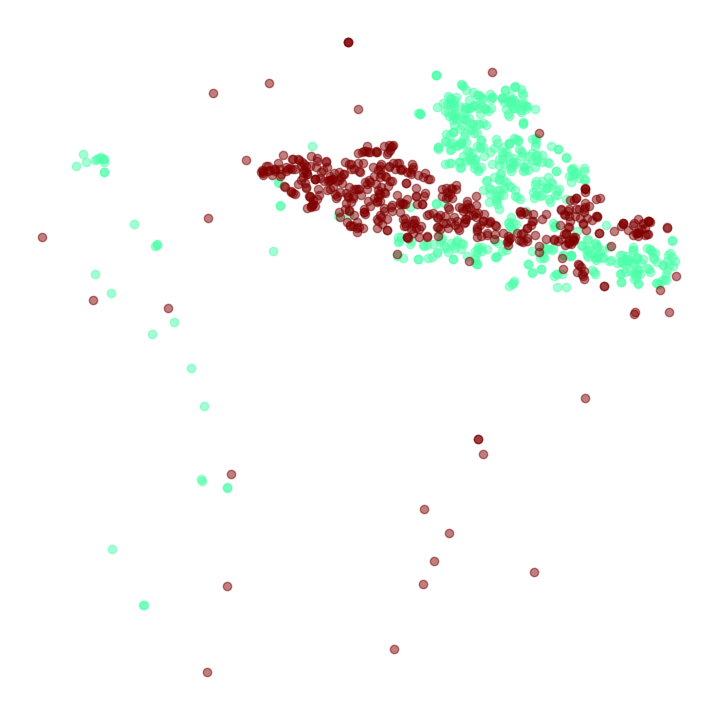

In [52]:
plt.figure(figsize=(9, 9))
cmap = plt.cm.jet
for digit in ("4", "9"):
    plt.scatter(
        X_reduced[y_sample == digit, 0],
        X_reduced[y_sample == digit, 1],
        c=[cmap(float(digit) / 9)],
        alpha=0.5,
    )
plt.axis("off")
plt.show()

> Let’s see if we can produce a nicer image by running t-SNE on just these 2 digits:

In [53]:
idx = (y_sample == "4") | (y_sample == "9")
X_subset = X_sample[idx]
y_subset = y_sample[idx]

tsne_subset = TSNE(
    n_components=2, init="random", learning_rate="auto", random_state=42
)
X_subset_reduced = tsne_subset.fit_transform(X_subset)

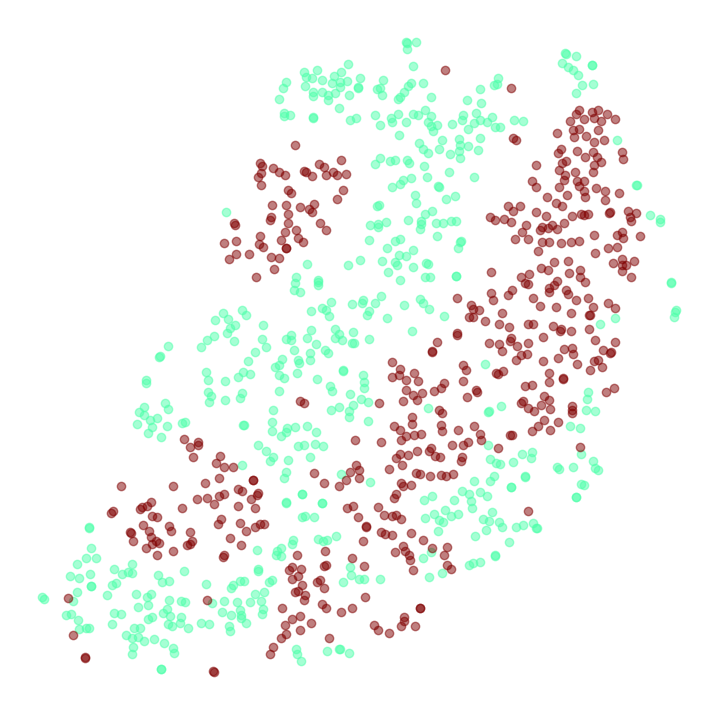

In [54]:
plt.figure(figsize=(9, 9))
for digit in ("4", "9"):
    plt.scatter(
        X_subset_reduced[y_subset == digit, 0],
        X_subset_reduced[y_subset == digit, 1],
        c=[cmap(float(digit) / 9)],
        alpha=0.5,
    )
plt.axis("off")
plt.show()

> That’s much better, although there’s still a bit of overlap. Perhaps some 4s really do look like 9s, and vice versa. It would be nice if we could visualize a few digits from each region of this plot, to understand what’s going on. In fact, let’s do that now.
>
> Alternatively, we can replace each dot in the scatterplot with the corresponding instance’s class (a digit from 0 to 9), or even plot scaled-down versions of the digit images themselves (if we plot all digits, the visualization will be too cluttered, so we should either draw a random sample or plot an instance only if no other instance has already been plotted at a close distance). We should get a nice visualization with well-separated clusters of digits.
>
> Let’s create a `plot_digits()` function that will draw a scatterplot (similar to the above scatterplots) plus write colored digits, with a minimum distance guaranteed between these digits. If the digit images are provided, they are plotted instead. This implementation was inspired from one of Scikit-Learn’s excellent examples ([plot_lle_digits](https://scikit-learn.org/stable/auto_examples/manifold/plot_lle_digits.html), based on a different digit dataset).

In [55]:
from typing import Optional

from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from sklearn.preprocessing import MinMaxScaler


def plot_digits(
    X: np.ndarray,
    y: np.ndarray,
    min_distance: float = 0.04,
    images: Optional[np.ndarray] = None,
    figsize: tuple[float, ...] = (13, 10),
) -> None:
    # Let’s scale the input features so that they range from 0 to 1
    X_normalized = MinMaxScaler().fit_transform(X)
    # Now we create the list of coordinates of the digits plotted so
    # far.
    # We pretend that one is already plotted far away at the start, to
    # avoid `if` statements in the loop below
    neighbors = np.array([[10.0, 10.0]])
    # The rest should be self-explanatory
    plt.figure(figsize=figsize)
    cmap = plt.cm.jet
    digits = np.unique(y)
    for digit in digits:
        plt.scatter(
            X_normalized[y == digit, 0],
            X_normalized[y == digit, 1],
            c=[cmap(float(digit) / 9)],
            alpha=0.5,
        )
    plt.axis("off")
    # Get current axes
    ax = plt.gca()
    for index, image_coord in enumerate(X_normalized):
        closest_distance = np.linalg.norm(
            neighbors - image_coord, axis=1
        ).min()
        if closest_distance > min_distance:
            neighbors = np.r_[neighbors, [image_coord]]
            if images is None:
                plt.text(
                    image_coord[0],
                    image_coord[1],
                    str(int(y[index])),
                    color=cmap(float(y[index]) / 9),
                    fontdict={"weight": "bold", "size": 16},
                )
            else:
                image = images[index].reshape(28, 28)
                imagebox = AnnotationBbox(
                    OffsetImage(image, cmap="binary"), image_coord
                )
                ax.add_artist(imagebox)

> Let’s try it! First let’s show colored digits (not images), for all 5,000 images:

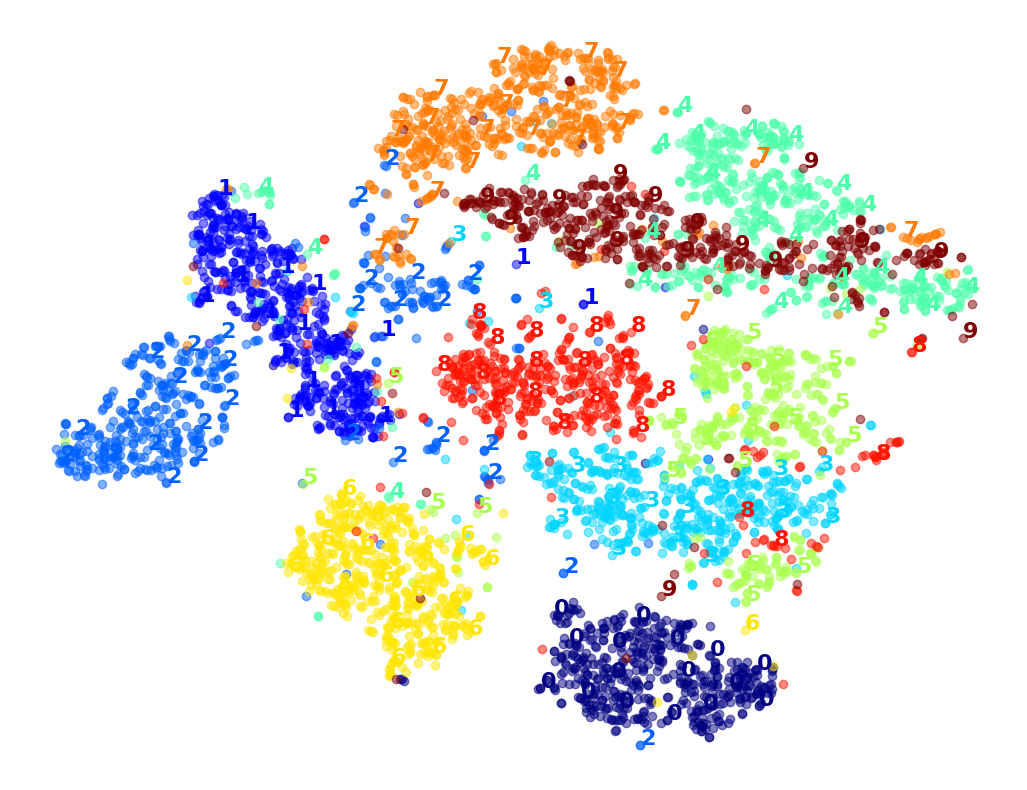

In [56]:
plot_digits(X_reduced, y_sample)

> Well that’s okay, but not that beautiful. Let’s try with the digit images:

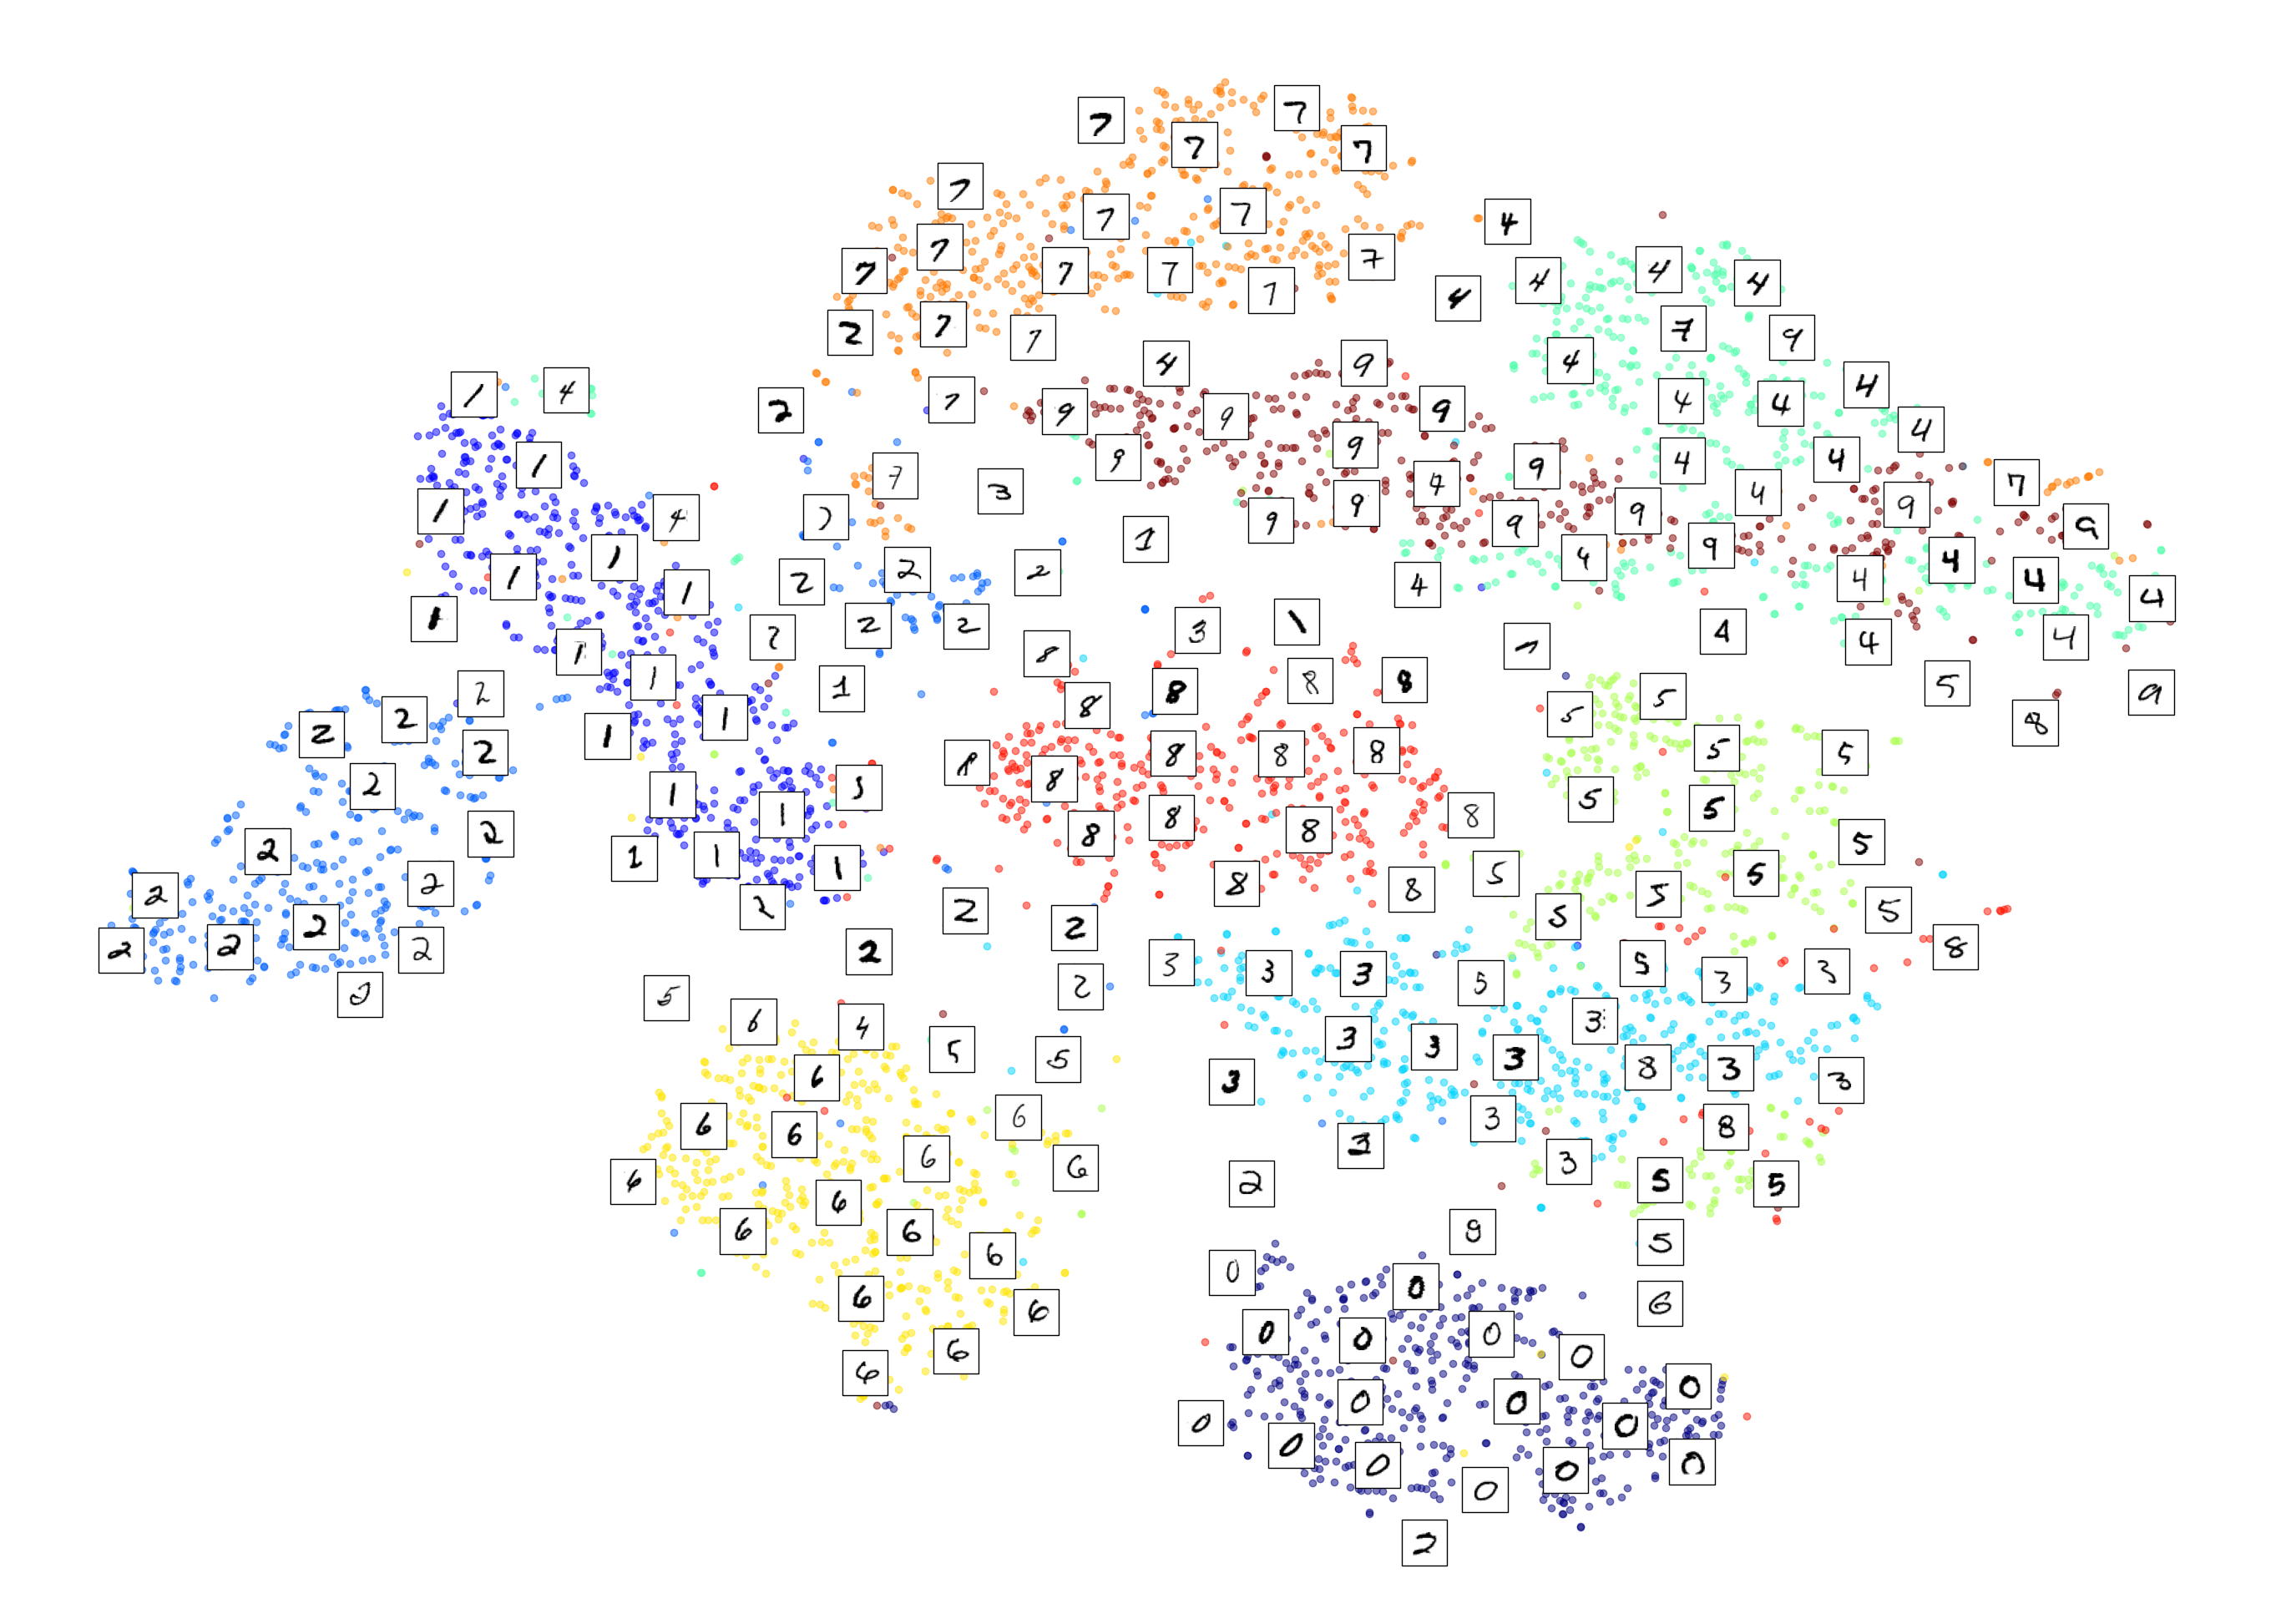

In [57]:
plot_digits(X_reduced, y_sample, images=X_sample, figsize=(35, 25))

> That’s nicer! Now let’s focus on just the 4s and the 9s:

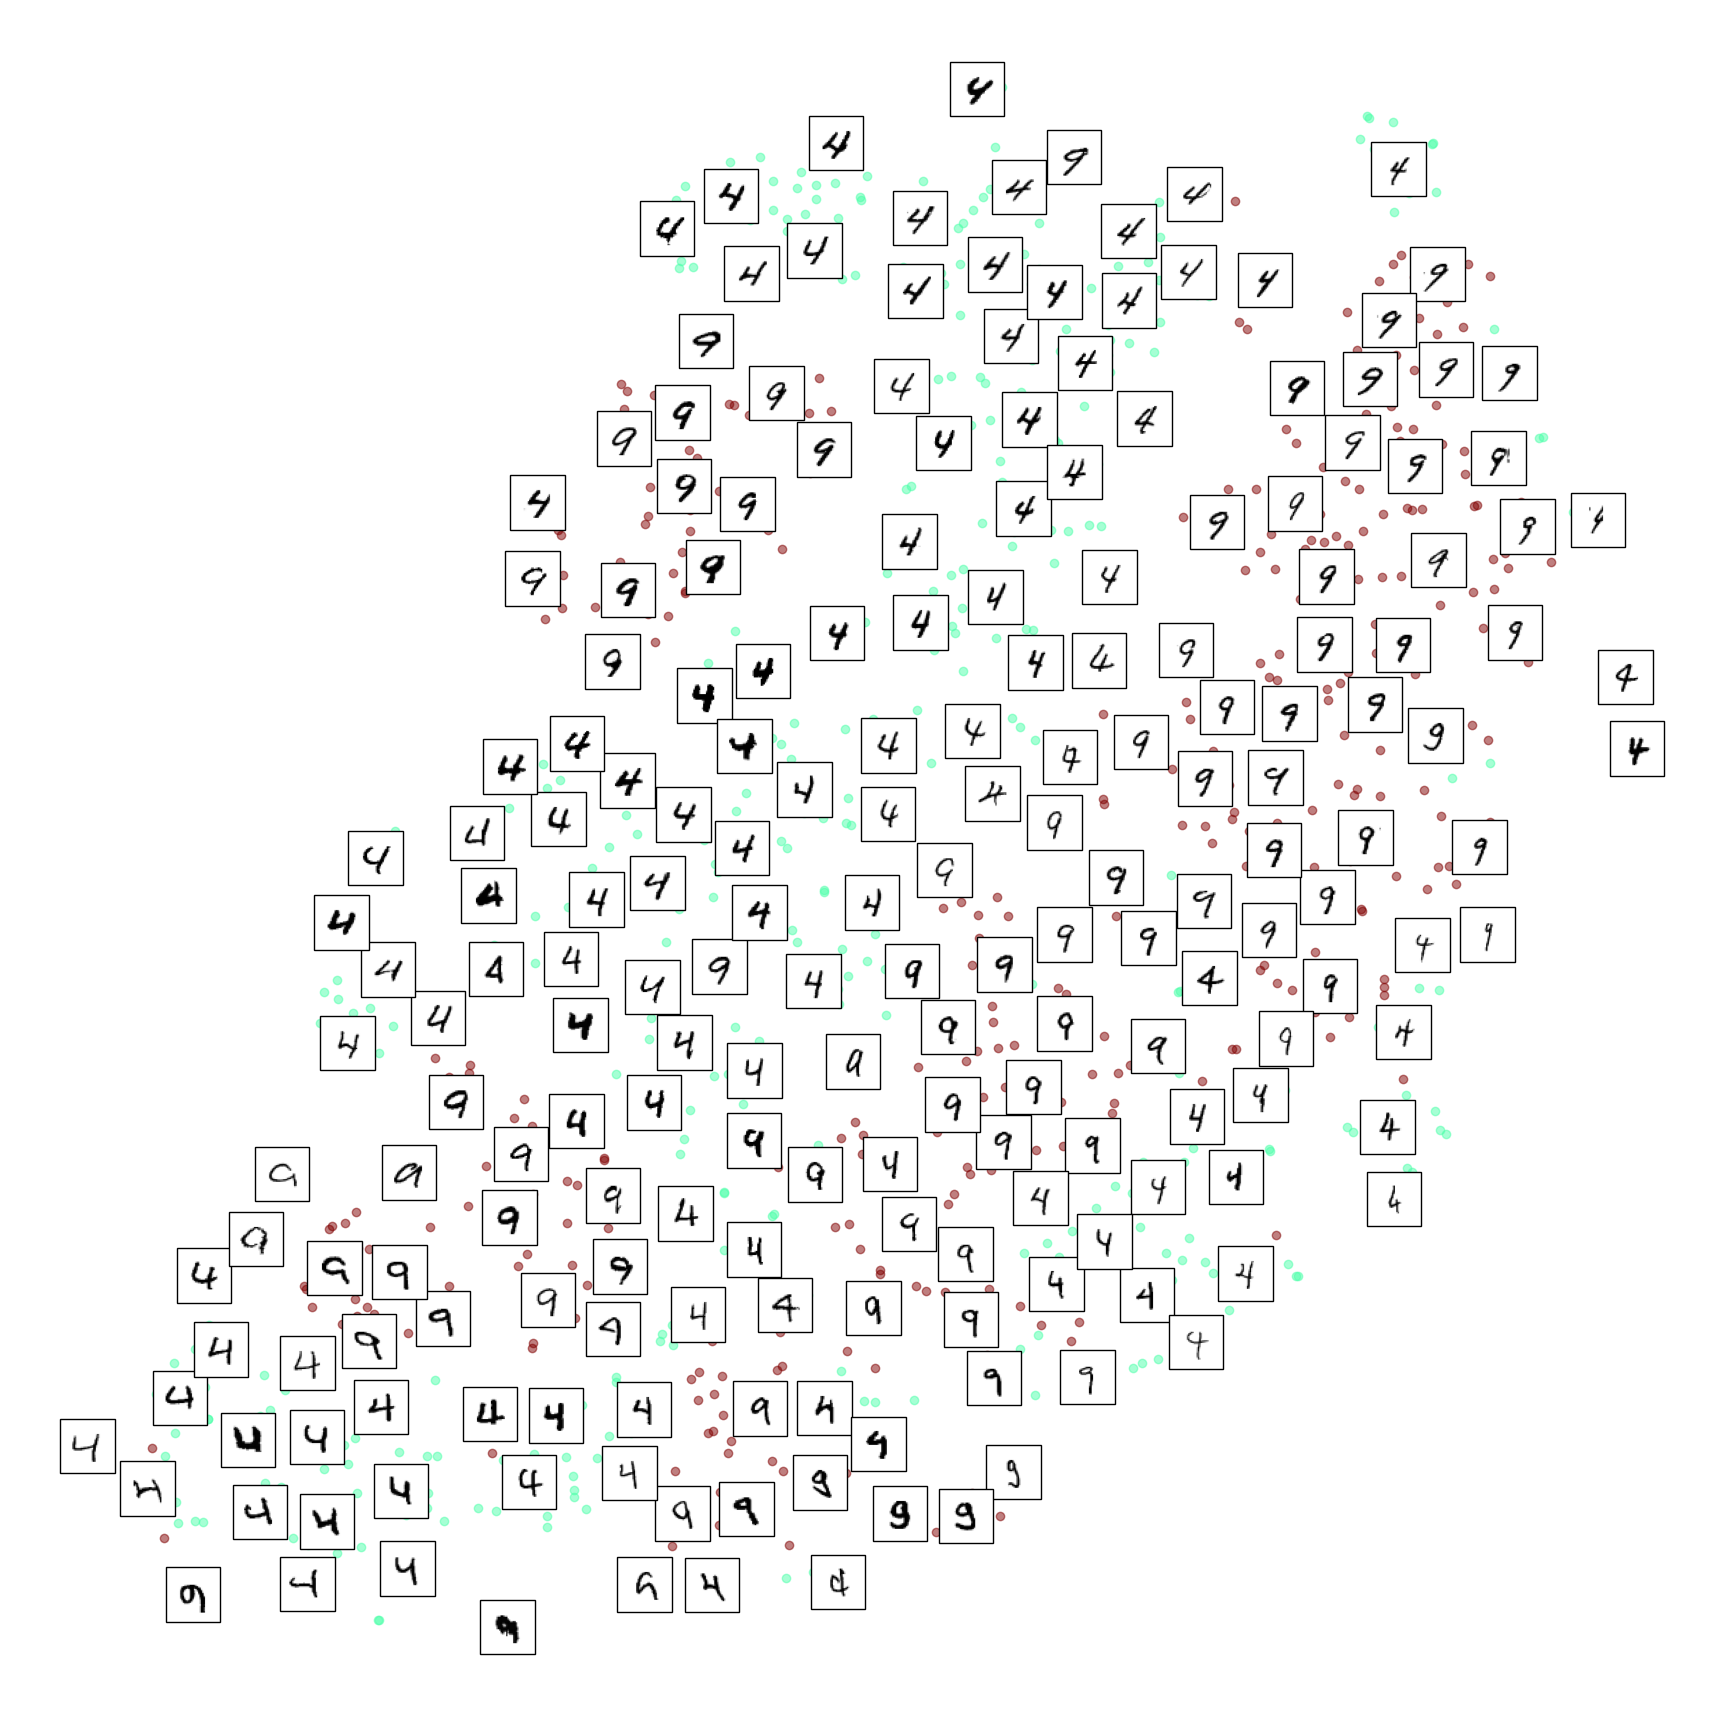

In [58]:
plot_digits(X_subset_reduced, y_subset, images=X_subset, figsize=(22, 22))

> Notice how similar-looking 4s are grouped together. For example, the 4s get more and more inclined as they approach the top of the figure. The inclined 9s are also closer to the top. Some 4s really do look like 9s, and vice versa.

Try using other dimensionality reduction algorithms such as PCA, LLE, or MDS and compare the resulting visualizations.
> Let’s start with PCA. We will also time how long it takes:

In [59]:
pca = PCA(n_components=2, random_state=42)

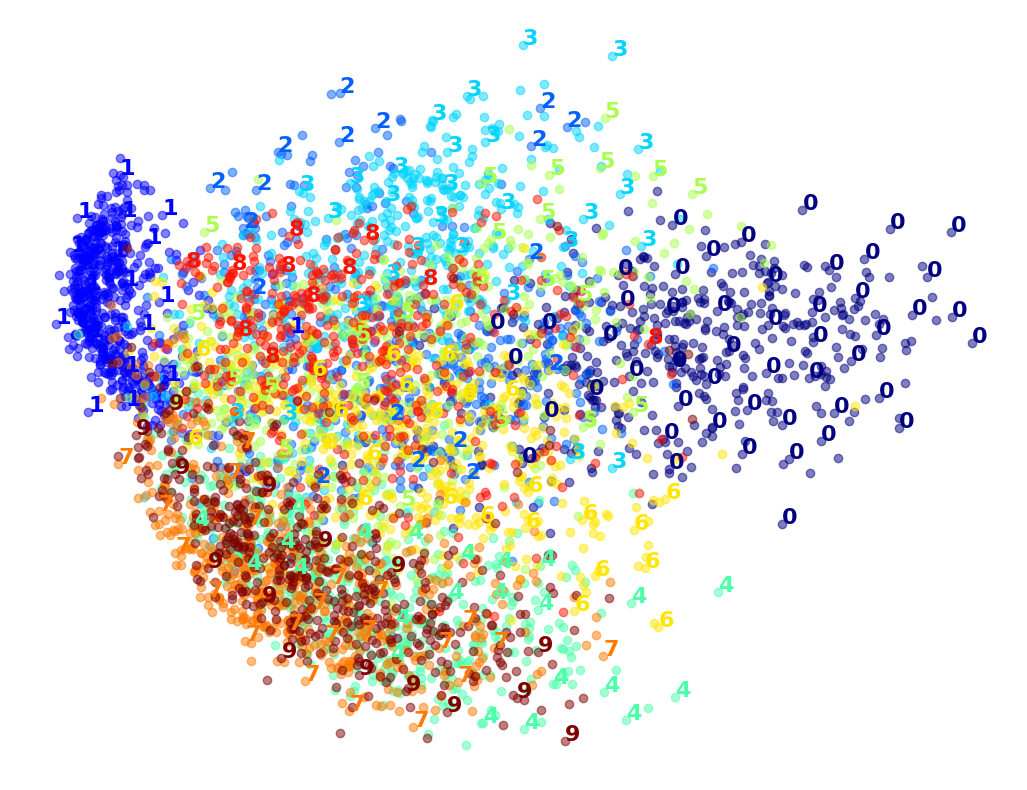

CPU times: user 132 ms, sys: 6.41 ms, total: 138 ms
Wall time: 134 ms


In [60]:
%%time
X_pca_reduced = pca.fit_transform(X_sample)
plot_digits(X_pca_reduced, y_sample)
plt.show()

> Wow, PCA is blazingly fast! But although we do see a few clusters, there’s way too much overlap. Let’s try LLE:

In [61]:
lle = LocallyLinearEmbedding(n_components=2, random_state=42)

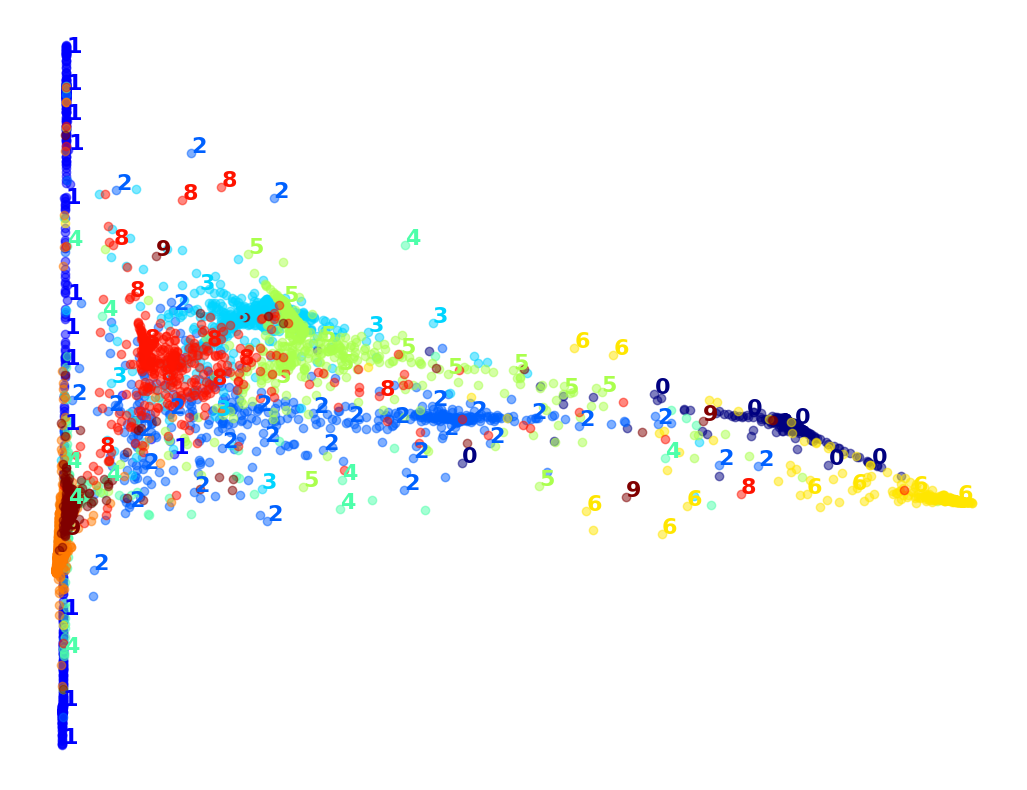

CPU times: user 1.82 s, sys: 1.46 s, total: 3.28 s
Wall time: 741 ms


In [62]:
%%time
X_lle_reduced = lle.fit_transform(X_sample)
plot_digits(X_lle_reduced, y_sample)
plt.show()

> That took more time, and yet the result does not look good at all. Let’s see what happens if we apply PCA first, preserving 95% of the variance:

In [63]:
pca_lle = make_pipeline(
    PCA(n_components=0.95),
    LocallyLinearEmbedding(n_components=2, random_state=42),
)

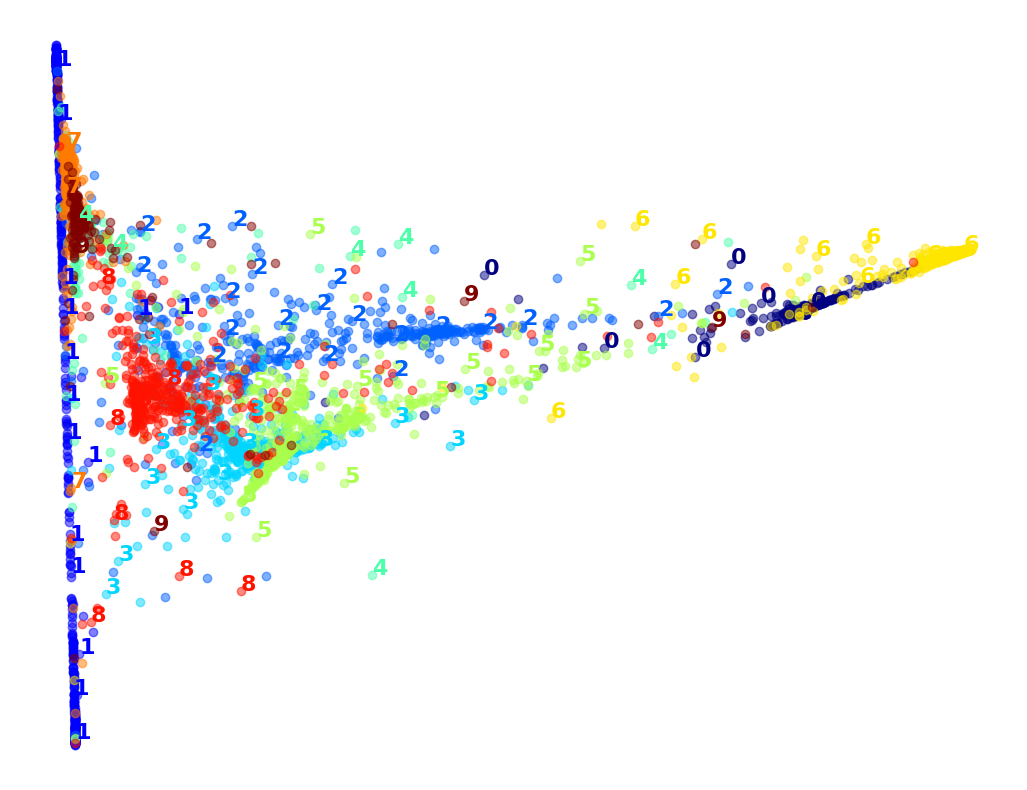

CPU times: user 1.57 s, sys: 1.48 s, total: 3.05 s
Wall time: 722 ms


In [64]:
%%time
X_pca_lle_reduced = pca_lle.fit_transform(X_sample)
plot_digits(X_pca_lle_reduced, y_sample)
plt.show()

> The result is more or less as bad, but this time training was a bit faster.
>
> Let’s try MDS:
>
> **Warning**: The following cell will take several minutes to run.

In [65]:
mds = MDS(n_components=2, n_init=4, random_state=42)

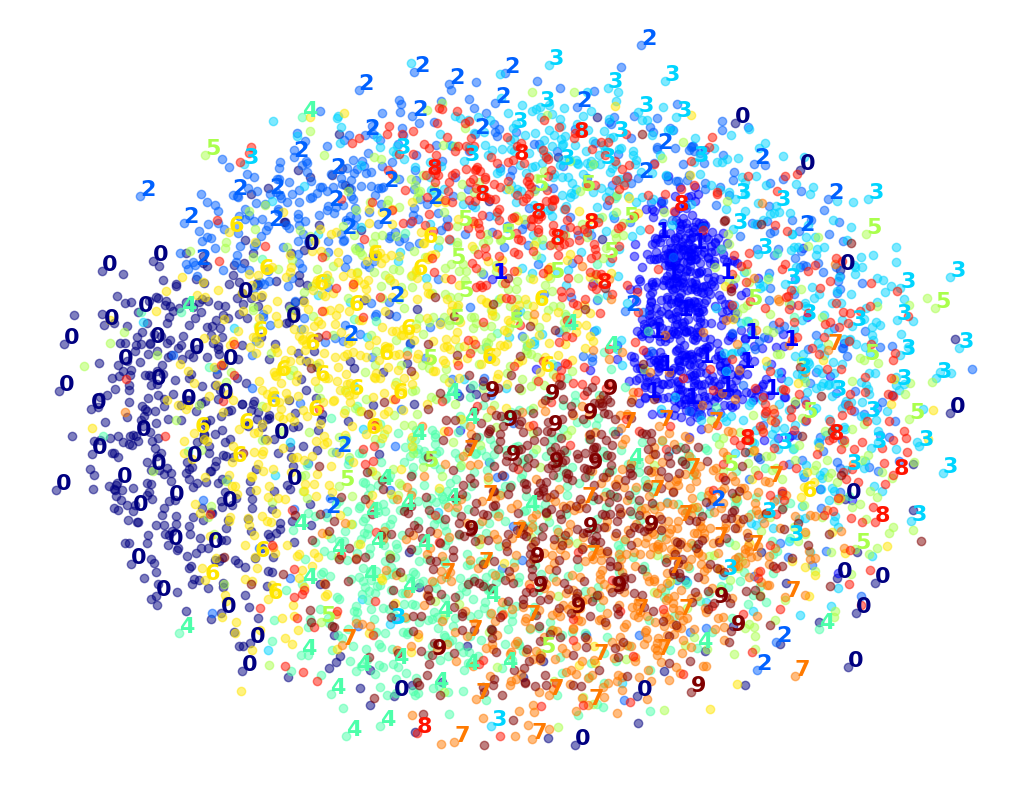

CPU times: user 2min 1s, sys: 2.79 s, total: 2min 4s
Wall time: 1min 53s


In [66]:
%%time
X_mds_reduced = mds.fit_transform(X_sample)
plot_digits(X_mds_reduced, y_sample)
plt.show()

> Meh. This does not look great, all clusters overlap too much. Let’s try with PCA first, perhaps it will be faster?
>
> **Warning**: The following cell will take several minutes to run.

In [67]:
pca_mds = make_pipeline(
    PCA(n_components=0.95, random_state=42),
    MDS(n_components=2, n_init=4, random_state=42),
)

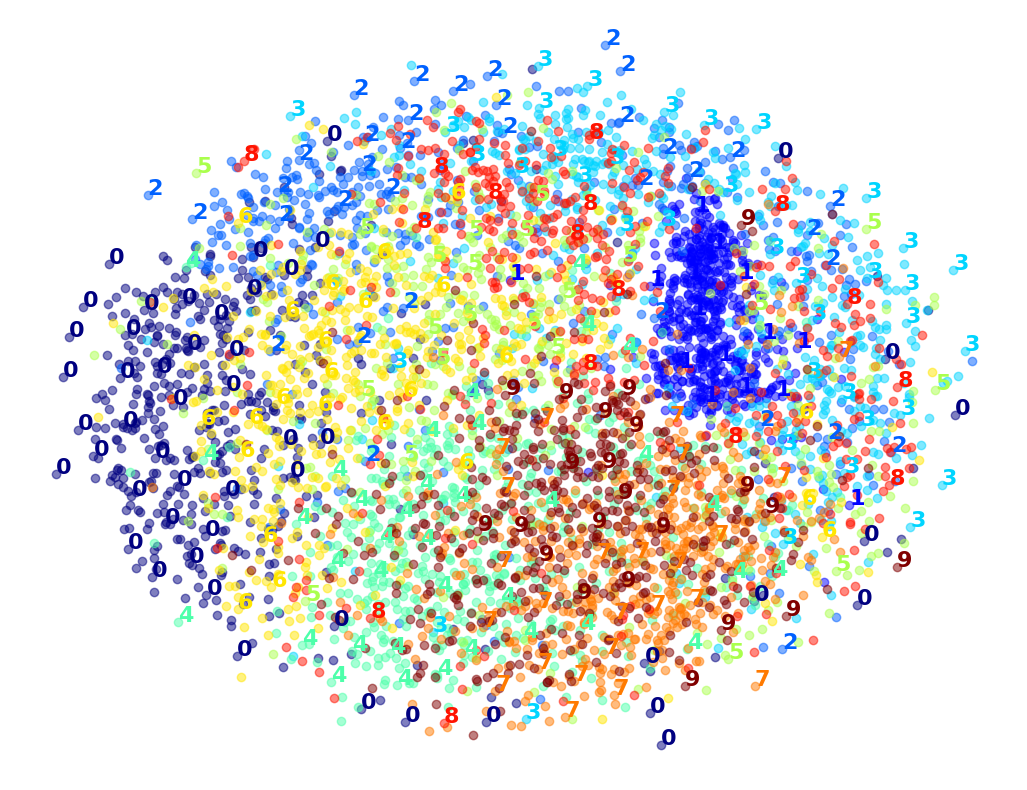

CPU times: user 2min 2s, sys: 4.1 s, total: 2min 6s
Wall time: 1min 55s


In [68]:
%%time
X_pca_mds_reduced = pca_mds.fit_transform(X_sample)
plot_digits(X_pca_mds_reduced, y_sample)
plt.show()

> Same result, and not faster: PCA did not help in this case.
>
> Let’s try LDA now:

In [69]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2)

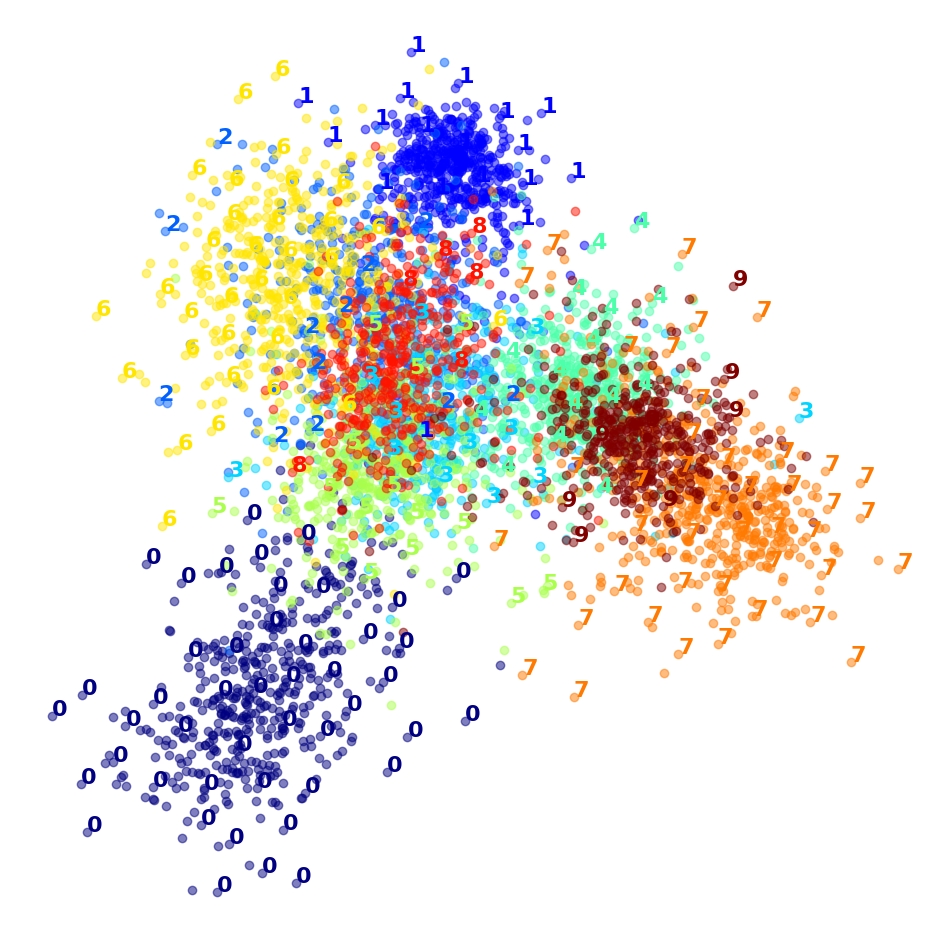

CPU times: user 298 ms, sys: 15 ms, total: 314 ms
Wall time: 273 ms


In [70]:
%%time
X_lda_reduced = lda.fit_transform(X_sample, y_sample)
plot_digits(X_lda_reduced, y_sample, figsize=(12, 12))
plt.show()

> This one is very fast, and it looks nice at first, until you realize that several clusters overlap severely.
>
> Well, it’s pretty clear that t-SNE won this little competition, wouldn’t we agree?